In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from google.colab import drive
import pandas as pd

# 2. Load the dataset from MyDrive
path = '/content/drive/MyDrive/Airplane_Crashes_and_Fatalities_Since_1908.csv'
dataset = pd.read_csv(path)



Mounted at /content/drive


In [ ]:
rows, columns = dataset.shape
print(f"Number of rows: {rows}")
print(f"Number of colums: {columns}")

Number of rows: 5268
Number of colums: 13


In [ ]:
dataset.tail(75)

,Date,Time,Location,Operator,Flight #,Route,Type,Registration,cn/In,Aboard,Fatalities,Ground,Summary
5193,03/15/2008,08:15,"Nbagu, Nigeria",Trade Wings Aviation Ltd.,NaN,Lagos - Bebi Air Strip,Beechcraft 1900D,5N-JAH,UE-322,3.0,3.0,0.0,The plane crashed while en route. Wreckage was...
5194,04/03/2008,11:00,"Lawa, Suriname",Blue Wing Airlines,NaN,Paramaribo - Lawa,Antonov An-28,PZ-TSO,1AJ007-17,19.0,19.0,0.0,While attempting to land the crew aborted the ...
5195,04/09/2008,23:27,"Bundeena, Australia",Avtex Air Services,NaN,Sydney - Brisbane,Swearingen SA227AC Metroliner III,VH-OZA,AC-600,1.0,1.0,0.0,The pilot of the mail plane reported some mino...
5196,04/11/2008,22:15,"Chrisinau, Moldova",Kata Transportation,NaN,"Chrisinau, Moldova - Antalya, Turkey - Sudan",Antonov An-32,ST-AZL,3009,8.0,8.0,0.0,Just minutes after the take off the plane trie...
5197,04/15/2008,14:30,"Goma, Congo",Hewa Bora Airways,NaN,Goma - Kisangani - Kinshasa,McDonnell Douglas DC-9-51,9Q-CHN,47731,85.0,0.0,47.0,"While attempting to takeoff, the plane failed ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5263,05/20/2009,06:30,"Near Madiun, Indonesia",Military - Indonesian Air Force,NaN,Jakarta - Maduin,Lockheed C-130 Hercules,A-1325,1982,112.0,98.0,2.0,"While on approach, the military transport cras..."
5264,05/26/2009,NaN,"Near Isiro, DemocratiRepubliCongo",Service Air,NaN,Goma - Isiro,Antonov An-26,9Q-CSA,5005,4.0,4.0,NaN,The cargo plane crashed while on approach to I...
5265,06/01/2009,00:15,"AtlantiOcean, 570 miles northeast of Natal, Br...",Air France,447,Rio de Janeiro - Paris,Airbus A330-203,F-GZCP,660,228.0,228.0,0.0,The Airbus went missing over the AtlantiOcean ...
5266,06/07/2009,08:30,"Near Port Hope Simpson, Newfoundland, Canada",Strait Air,NaN,Lourdes de BlanSablon - Port Hope Simpson,Britten-Norman BN-2A-27 Islander,C-FJJR,424,1.0,1.0,0.0,The air ambulance crashed into hills while att...


In [ ]:
print(dataset.isnull().sum())
"""
Treatment Methods for the Missing Data

1. Text Data (Time, Operator, Flight #, Route, Type, Registration, cn/In, Summary)
For Time, Location, Operator, Route, Type and Summary:
Method: Input the missing values with 'Undefined'
Justification:Text cannot be mathematically averaged. While we could use the mode which is the most frequent value, doing so would unfairly attribute unknown crashes to the most popular airlines or locations in the dataset, falsifying historical records.
For Flight #, Registration, cn/In:
Method: Input the missing values with 'Undefined'
Justoification: These are unique categorical identifiers. They hold no statistical pattern to predict.

2. Numerical Data (Aboard, Fatalities and Ground)
For Aboard and Fatalities:
Method: Input the missing values with Median.
Justification: Aviation accidents vary wildly in size (from 2-seater planes to massive commercial jets). The median prevents extreme outliers from skewing the typical passenger count.
For Ground:
Method: Input the missing values with 0
Justification: In crash reports, a blank ground casualty field overwhelmingly means no one on the ground was killed.
"""

Date               0
Time            2219
Location          20
Operator          18
Flight #        4199
Route           1707
Type              27
Registration     335
cn/In           1228
Aboard            22
Fatalities        12
Ground            22
Summary          390
dtype: int64


"\nTreatment Methods for the Missing Data\n\n1. Text Data (Time, Operator, Flight #, Route, Type, Registration, cn/In, Summary)\nFor Time, Location, Operator, Route, Type and Summary:\nMethod: Input the missing values with 'Undefined'\nJustification:Text cannot be mathematically averaged. While we could use the mode which is the most frequent value, doing so would unfairly attribute unknown crashes to the most popular airlines or locations in the dataset, falsifying historical records.\nFor Flight #, Registration, cn/In:\nMethod: Input the missing values with 'Undefined'\nJustoification: These are unique categorical identifiers. They hold no statistical pattern to predict.\n\n2. Numerical Data (Aboard, Fatalities and Ground)\nFor Aboard and Fatalities:\nMethod: Input the missing values with Median.\nJustification: Aviation accidents vary wildly in size (from 2-seater planes to massive commercial jets). The median prevents extreme outliers from skewing the typical passenger count.\nFor 

In [ ]:
fatality_locations = dataset[['Date', 'Location', 'Aboard', 'Fatalities']].copy()


In [ ]:
max_fatalities=fatality_locations['Fatalities'].max()
result= fatality_locations[fatality_locations['Fatalities']==max_fatalities]
result['Date']

,Date
2963,03/27/1977


In [ ]:
columns_to_study=['Aboard','Fatalities']
dataset[columns_to_study]

,Aboard,Fatalities
0,2.0,1.0
1,5.0,5.0
2,1.0,1.0
3,20.0,14.0
4,30.0,30.0
...,...,...
5263,112.0,98.0
5264,4.0,4.0
5265,228.0,228.0
5266,1.0,1.0


In [ ]:
split_location = fatality_locations['Location'].astype(str).str.rsplit(',', n=1, expand=True)
fatality_locations['Region'] = split_location[0].str.strip()
fatality_locations['State_Country'] = split_location[1].str.strip()
display(fatality_locations[['Location', 'Region','State_Country']])

,Location,Region,State_Country
0,"Fort Myer, Virginia",Fort Myer,Virginia
1,"AtlantiCity, New Jersey",AtlantiCity,New Jersey
2,"Victoria, British Columbia, Canada","Victoria, British Columbia",Canada
3,Over the North Sea,Over the North Sea,None
4,"Near Johannisthal, Germany",Near Johannisthal,Germany
...,...,...,...
5263,"Near Madiun, Indonesia",Near Madiun,Indonesia
5264,"Near Isiro, DemocratiRepubliCongo",Near Isiro,DemocratiRepubliCongo
5265,"AtlantiOcean, 570 miles northeast of Natal, Br...","AtlantiOcean, 570 miles northeast of Natal",Brazil
5266,"Near Port Hope Simpson, Newfoundland, Canada","Near Port Hope Simpson, Newfoundland",Canada


In [ ]:
top_100_crashes = fatality_locations.sort_values(by='Fatalities', ascending=False).head(100)
top_100_crashes

,Date,Location,Aboard,Fatalities,Region,State_Country
2963,03/27/1977,"Tenerife, Canary Islands",644.0,583.0,Tenerife,Canary Islands
3568,08/12/1985,"Mt. Osutaka, near Ueno Village, Japan",524.0,520.0,"Mt. Osutaka, near Ueno Village",Japan
4455,11/12/1996,"Near Charkhidadri, India",349.0,349.0,Near Charkhidadri,India
2726,03/03/1974,"Near Ermenonville, France",346.0,346.0,Near Ermenonville,France
3562,06/23/1985,"AtlantiOcean, 110 miles West of Ireland",329.0,329.0,AtlantiOcean,110 miles West of Ireland
...,...,...,...,...,...,...
4852,04/15/2002,"Busan, South Korea",166.0,128.0,Busan,South Korea
3198,01/21/1980,"Elburz Mtns., near Laskarak, Markazi, Iran",128.0,128.0,"Elburz Mtns., near Laskarak, Markazi",Iran
1701,12/16/1960,"Staten Island / Brooklyn, New York",128.0,128.0,Staten Island / Brooklyn,New York
5108,07/09/2006,"Irkutsk, Russia",203.0,128.0,Irkutsk,Russia


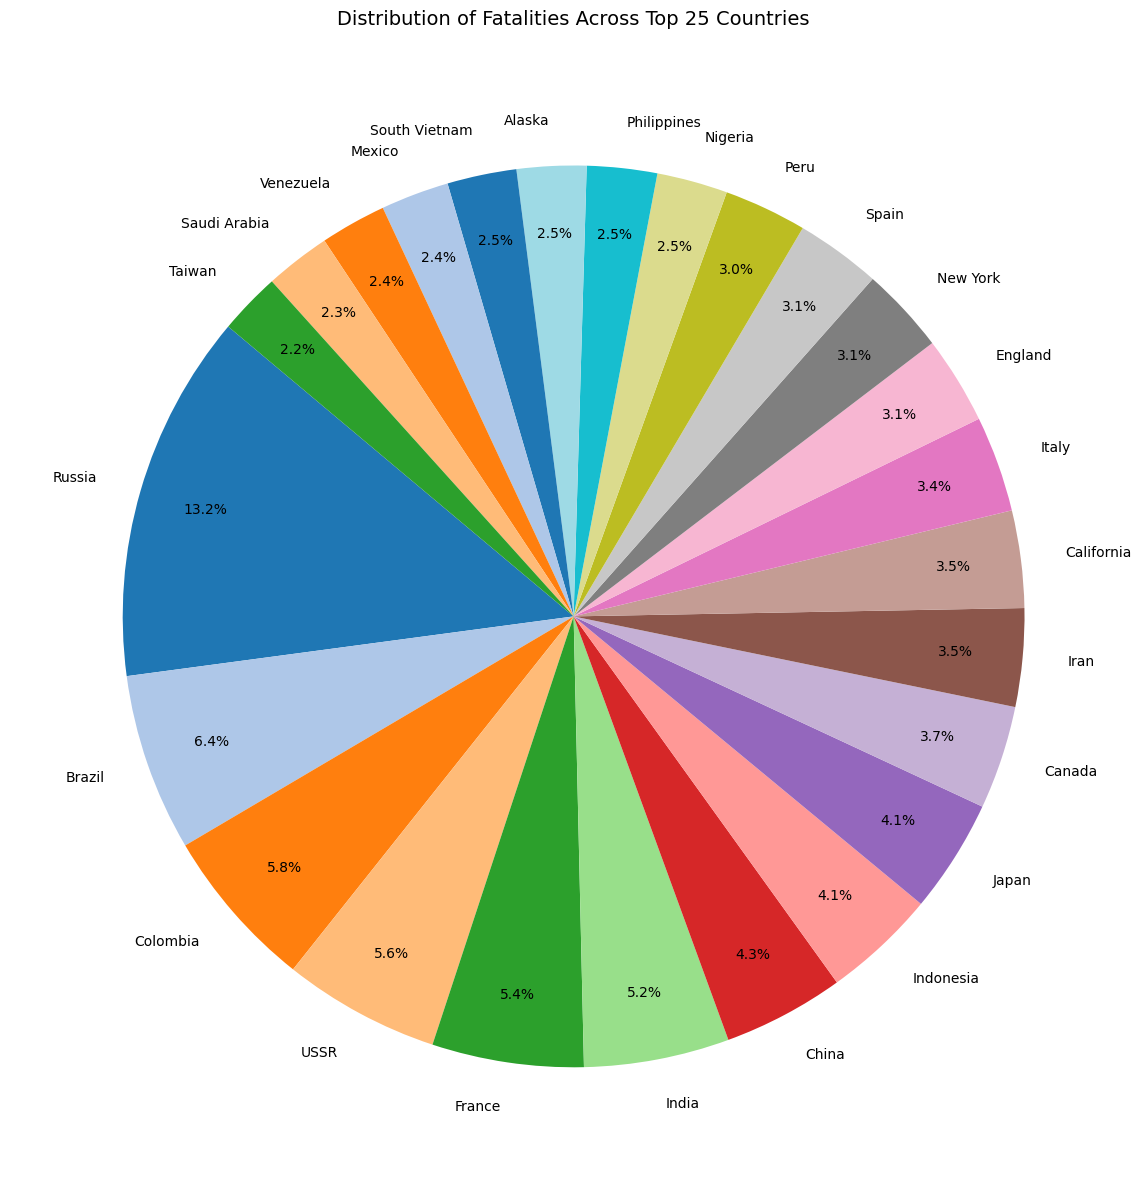

In [ ]:

import matplotlib.pyplot as chart
import seaborn as slt


top_25 = (
    fatality_locations.groupby('State_Country')['Fatalities']
    .sum()
    .sort_values(ascending=False)
    .head(25)
)

chart.figure(figsize=(12, 12))

colors = slt.color_palette('tab20', len(top_25))

chart.pie(
    top_25.values,
    labels=top_25.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    pctdistance=0.85
)

chart.title('Distribution of Fatalities Across Top 25 Countries', fontsize=14, pad=20)
chart.tight_layout()
chart.show()

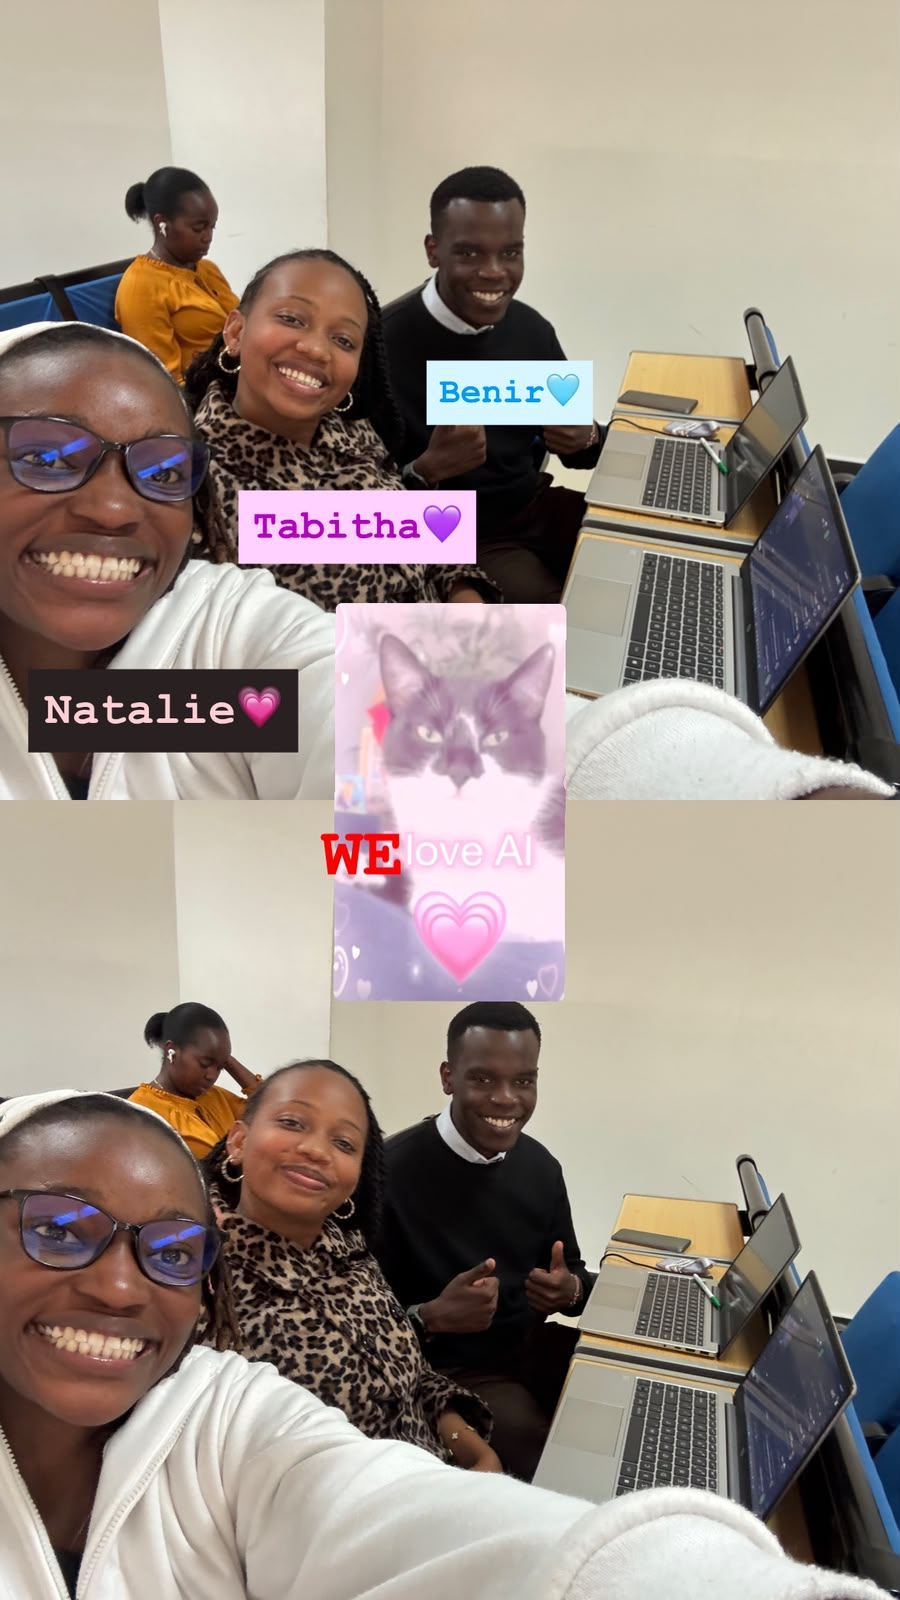

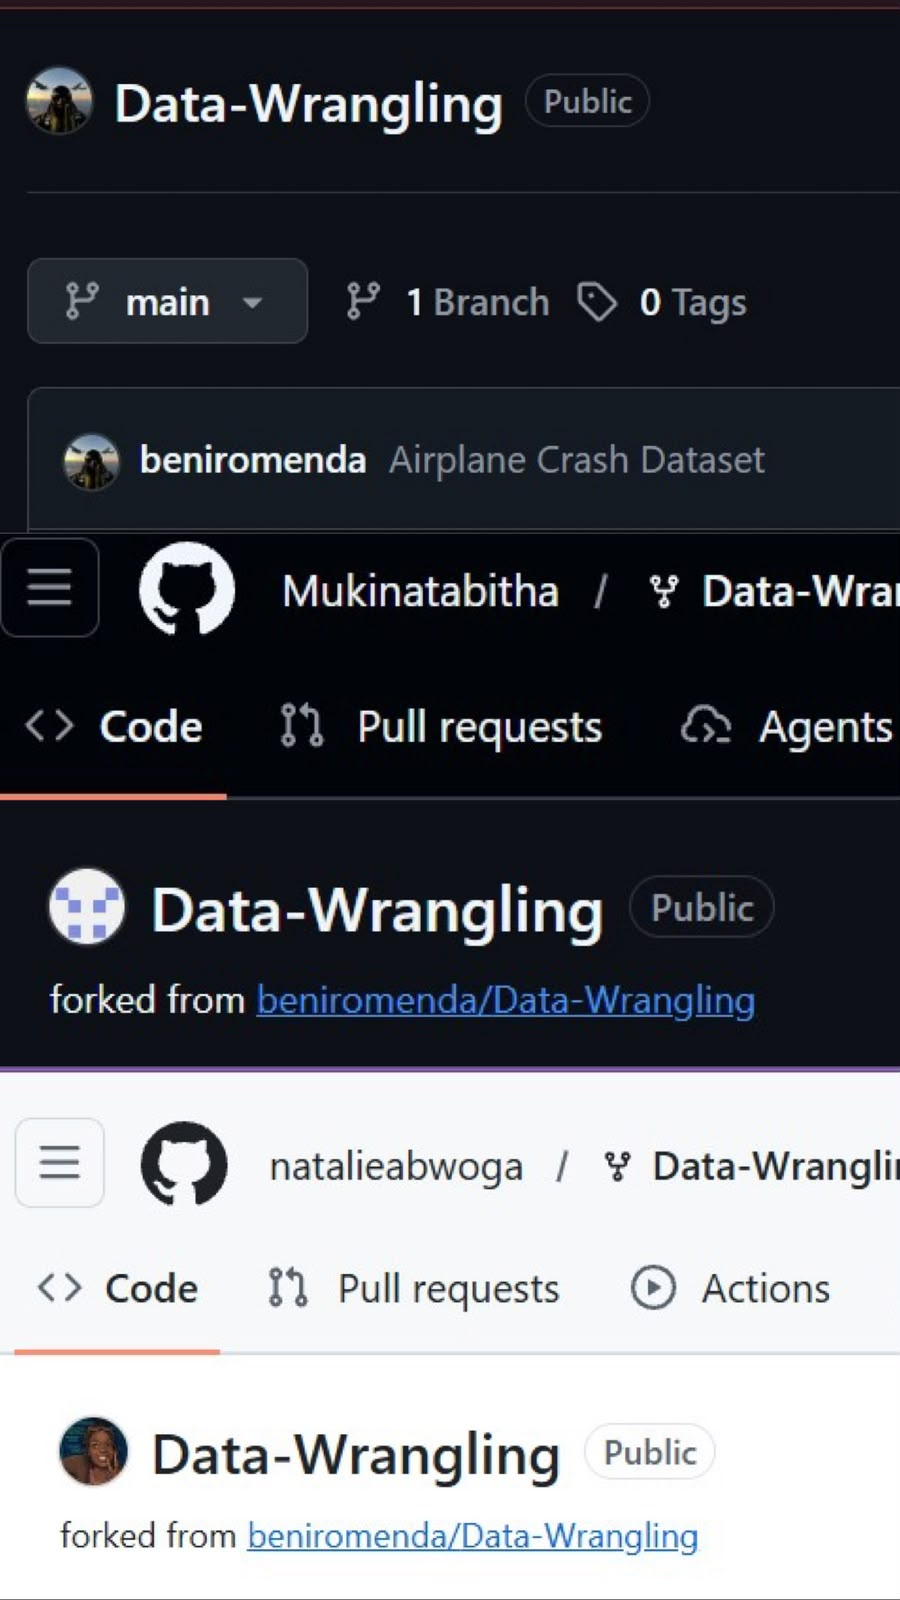